# 01 · Calidad de datos y arquitectura medallion — Conecta+

**Objetivo de la fase:** entender las 7 fuentes, documentar cada problema con evidencia y dejar
datos limpios y trazables para modelar.

| Capa | Qué contiene | Regla |
|---|---|---|
| **Bronze** | Copia fiel de cada fuente + metadatos (`_fila`, `_fuente`, `_sha256_fuente`, `_ingestado_en`) | No se corrige nada |
| **Silver** | Entidades limpias, tipadas, deduplicadas, en hora local Bogotá | Cada corrección deja flag u original |
| **Gold** | Tablas listas para modelar (hoy: *spine* cliente × fecha de corte) | Todo "al corte" (point-in-time) |

Código: paquete `conecta/` (`bronze.py`, `silver.py`, `gold.py`, `quality.py`, `pipeline.py`).
Cada problema tiene un código **Pxx** que se repite en el código, el reporte y este notebook.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd, numpy as np, matplotlib.pyplot as plt
from conecta import pipeline, io, config
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 200)

# Estilo de gráficos: marcas finas, grilla tenue, sin ejes duplicados
AZUL, NARANJA, TINTA, TENUE = "#2a78d6", "#eb6834", "#2b2b2b", "#8a8a86"
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": TENUE, "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelcolor": TINTA,
                     "xtick.color": TENUE, "ytick.color": TENUE, "lines.linewidth": 2, "figure.facecolor": "#fcfcfb",
                     "axes.facecolor": "#fcfcfb", "axes.axisbelow": True})
LAKE = RAIZ / "lake"
reporte = pipeline.run(data_dir=config.DATA_DIR, lake_dir=LAKE)

[bronze] 7 tablas  (0.7s)


[silver] 7 tablas  (2.0s)


[gold] 2 tablas  (3.3s)


[calidad] 42 checks · 0 fallas


## 1. Volumen por capa
Filas en bronze vs silver: la diferencia son duplicados eliminados.

In [2]:
tablas = ["clientes", "suscripciones", "facturas", "tickets", "eventos", "etiquetas_entrenamiento", "clientes_a_puntuar"]
vol = pd.DataFrame({"bronze": [len(io.read(LAKE, "bronze", t)) for t in tablas],
                    "silver": [len(io.read(LAKE, "silver", t)) for t in tablas]}, index=tablas)
vol["eliminadas"] = vol.bronze - vol.silver
vol

,bronze,silver,eliminadas
clientes,3000,3000,0
suscripciones,3372,3372,0
facturas,34877,34098,779
tickets,4678,4678,0
eventos,104752,103289,1463
etiquetas_entrenamiento,4810,4810,0
clientes_a_puntuar,1558,1558,0


## 2. Reporte de calidad
`detectado` = problema medido en bronze · `ok`/`FALLA` = verificación en silver · `info` = a tratar en gold.

In [3]:
reporte[["capa", "tabla", "codigo", "regla", "n_afectados", "pct", "severidad", "estado", "accion"]]

,capa,tabla,codigo,regla,n_afectados,pct,severidad,estado,accion
0,bronze,clientes,P01,ciudad escrita con variantes (17 valores para 6 ciudades),2000,66.67,media,detectado,Normalizar a nombre canónico
1,bronze,clientes,P02,"edad fuera de [18,90] (centinelas 0/99/999)",85,2.83,media,detectado,Reemplazar por NaN + flag
2,bronze,clientes,P03,contacto de retención anterior a la fecha de alta,76,2.53,baja,detectado,Marcar flag; no usar esa fecha
3,bronze,clientes,P04,estado_actual refleja HOY (fuga para cortes pasados),3000,100.00,alta,detectado,Excluir de features
4,bronze,suscripciones,P05,suscripciones cerradas por cambio de plan (no son churn),372,11.03,alta,detectado,Churn = fin de la ÚLTIMA suscripción
5,bronze,facturas,P06,"factura_id duplicado (recarga día 5, 07:00)",779,2.23,alta,detectado,"Deduplicar, conservar primera carga"
6,bronze,facturas,P07,facturas sin fecha_pago (pago se actualiza sin fecha de carga),1457,4.18,alta,detectado,Pago conocido solo si fecha_pago <= corte
7,bronze,facturas,P08,monto del Básico = 19.900 (precio anterior a abr-2025),5784,16.58,info,detectado,No es error: subida de precio (hallazgo)
8,bronze,tickets,P09,dos esquemas JSON distintos (3 combinaciones de claves),2468,52.76,alta,detectado,Unificar A y B en un esquema
9,bronze,tickets,P10,ID de cliente con formato texto 'CL-0xxxxx' (esquema A),2210,47.24,alta,detectado,Convertir a entero


## 3. Evidencia por problema

### P09 · P12 — Tickets: la plataforma de atención cambió de esquema el 10-jun-2025
El esquema A (inglés, UTC) termina el 2025-06-10 y empieza el B (español, campos anidados, -05:00).
Sin unificar, la mitad de los tickets se perdería o se leería mal.

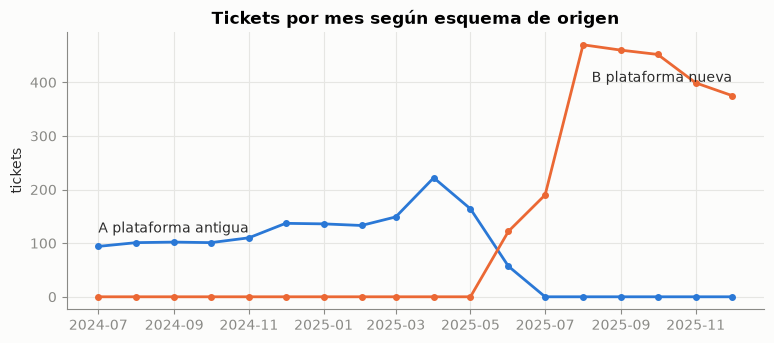

Último ticket A: 2025-06-09 20:50:00 | Primer ticket B: 2025-06-10 07:51:00


In [4]:
tk = io.read(LAKE, "silver", "tickets")
m = tk.groupby([tk.creado_en.dt.to_period("M"), "esquema"]).size().unstack(fill_value=0)
m = m.loc["2024-07":]
fig, ax = plt.subplots()
x = m.index.to_timestamp()
for col, color in zip(m.columns, [AZUL, NARANJA]):
    ax.plot(x, m[col], color=color, marker="o", markersize=4)
    i = 0 if col.startswith("A") else len(x) - 1
    ax.annotate(col.replace("_", " "), (x[i], m[col].iloc[i]), xytext=(0, 10), textcoords="offset points",
                color=TINTA, ha="left" if i == 0 else "right")
ax.set_title("Tickets por mes según esquema de origen"); ax.set_ylabel("tickets")
plt.show()
print("Último ticket A:", tk[tk.esquema.str.startswith("A")].creado_en.max(), "| Primer ticket B:", tk[tk.esquema.str.startswith("B")].creado_en.min())

**Zona horaria (P12):** 6 tickets B quedan en 2026-01-01 si se leen en UTC, pero en hora local son
del 31-dic-2025. Por eso todo se lleva a hora de Bogotá antes de cortar por fecha.

In [5]:
import json
b = io.read(LAKE, "bronze", "tickets")
raw = b.raw_json.map(json.loads)
fechas_b = pd.to_datetime(raw.map(lambda d: d.get("fecha")).dropna(), utc=True, format="ISO8601")
print("Tickets B en 2026 si se leen en UTC:", (fechas_b >= "2026-01-01").sum())
print("Tickets en 2026 en hora local (silver):", (tk.creado_en >= "2026-01-01").sum())

Tickets B en 2026 si se leen en UTC: 6
Tickets en 2026 en hora local (silver): 0


### P06 — Facturas cargadas dos veces
Mismo contenido, segunda carga el día 5 a las 07:00. Sin deduplicar se inflan pagos y mora.

In [6]:
fb = io.read(LAKE, "bronze", "facturas")
dup = fb[fb.factura_id.duplicated(keep=False)].sort_values(["factura_id", "fecha_carga"])
# Confidencialidad: no se muestran filas de facturas, solo el patrón de la duplicación
print("IDs duplicados:", dup.factura_id.nunique(), "| filas:", len(dup))
print("Horas de carga de las copias:", dup.fecha_carga.str[11:16].value_counts().to_dict())
print("Columnas que difieren entre las copias:", [c for c in fb.columns if c not in ("_fila", "fecha_carga")
      and dup.groupby("factura_id")[c].nunique().gt(1).any() and not c.startswith("_")])

IDs duplicados: 779 | filas: 1558
Horas de carga de las copias: {'02:00': 779, '07:00': 779}
Columnas que difieren entre las copias: []


### P01 · P02 — Ciudades y edades

In [7]:
cl = io.read(LAKE, "silver", "clientes")
display(cl.groupby("ciudad").ciudad_original.unique().to_frame("variantes en la fuente"))
print("Edades inválidas (valores):", io.read(LAKE, "bronze", "clientes").query("edad < 18 or edad > 90").edad.value_counts().to_dict())

,variantes en la fuente
ciudad,
Barranquilla,"[B/quilla, BARRANQUILLA, Barranquilla]"
Bogotá,"[bogota d.c., Bogota D.C., Bogotá, BOGOTA]"
Bucaramanga,"[Bucaramanga, BUCARAMANGA]"
Cali,"[Santiago de Cali, CALI, Cali]"
Medellín,"[medellin, MEDELLIN, Medellín]"
Pereira,"[Pereira, PEREIRA]"


Edades inválidas (valores): {999: 32, 0: 30, 99: 23}


### P05 — Qué es churn: un cambio de plan NO es cancelación
372 suscripciones terminan porque el cliente cambió de plan (continúa con otra suscripción el mismo día).
La regla *churn = termina la última suscripción del cliente en (corte, corte + 90 días]* reproduce
**4.810 / 4.810** etiquetas (check R09). Esto nos permite construir etiquetas para otros cortes si hiciera falta.

In [8]:
su = io.read(LAKE, "silver", "suscripciones")
pd.crosstab(su.motivo_cancelacion.fillna("(activa)"), su.fin_es_churn.map({True: "fin = churn", False: "no churn"}))

fin_es_churn,fin = churn,no churn
motivo_cancelacion,,
(activa),0,1558
calidad_servicio,242,0
cambio_plan,0,372
competencia,160,0
facturacion,136,0
no_lo_usa,186,0
otro,236,0
precio,171,0
problemas_tecnicos,311,0


### P04 · P03 — Fugas de información: `estado_actual` y el contacto de retención
- `estado_actual` es la foto de **hoy**: coincide 100 % con tener suscripción activa. Usarlo para cortes pasados es hacer trampa.
- El contacto de retención ocurre **3 a 19 días antes** de que el cliente se vaya: es reactivo (el cliente
  ya pidió cancelar). Si se cruza sin cuidar las fechas, el modelo "aprende" que contactar = cancelar.

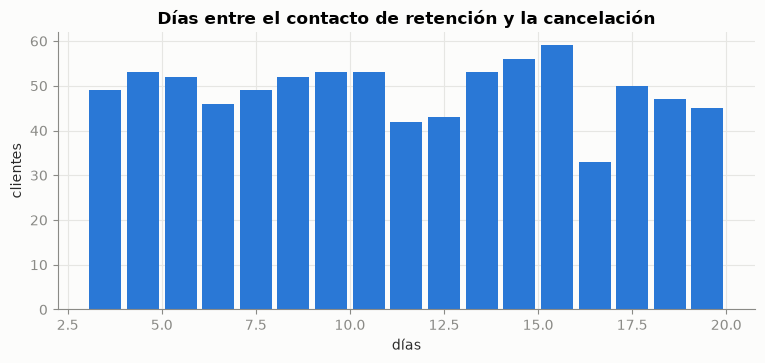

Contactados que igual cancelaron: 94%


,clientes,tasa_churn
contacto_en_ventana,,
False,4422,0.074
True,388,0.822


In [9]:
cl = io.read(LAKE, "silver", "clientes"); su = io.read(LAKE, "silver", "suscripciones")
fin = su[su.fin_es_churn].groupby("cliente_id").fecha_fin.max()
c = cl.set_index("cliente_id").join(fin.rename("fecha_churn"))
dias = (c.fecha_churn - c.fecha_contacto_retencion).dt.days.dropna()
fig, ax = plt.subplots()
ax.hist(dias, bins=range(int(dias.min()), int(dias.max()) + 2), color=AZUL, rwidth=0.85)
ax.set_title("Días entre el contacto de retención y la cancelación"); ax.set_xlabel("días"); ax.set_ylabel("clientes")
plt.show()
print(f"Contactados que igual cancelaron: {c.contactado_por_retencion.mean()*0 + (c[c.contactado_por_retencion].fecha_churn.notna().mean()):.0%}")
et = io.read(LAKE, "silver", "etiquetas_entrenamiento").merge(cl[["cliente_id", "fecha_contacto_retencion"]], on="cliente_id")
et["contacto_en_ventana"] = (et.fecha_contacto_retencion > et.fecha_corte) & (et.fecha_contacto_retencion <= et.fecha_corte + pd.Timedelta(days=90))
et.groupby("contacto_en_ventana").churn_90d.agg(clientes="size", tasa_churn="mean").round(3)

### P07 — Pagos: la fecha de pago se conoce después
`fecha_pago` no tiene fecha de carga propia. Para un corte, una factura vencida sin pago **hasta ese día**
cuenta como pendiente aunque después se haya pagado. Las facturas impagas suben desde mayo-2025
(dic-2025 incluye facturas que aún no vencen al corte).

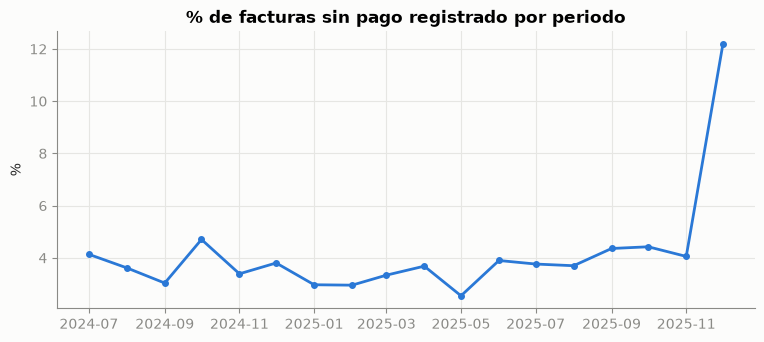

In [10]:
fa = io.read(LAKE, "silver", "facturas")
s = fa.groupby(fa.periodo.dt.to_period("M")).pagada.apply(lambda p: 1 - p.mean()).loc["2024-07":]
fig, ax = plt.subplots()
ax.plot(s.index.to_timestamp(), s.values * 100, color=AZUL, marker="o", markersize=4)
ax.set_title("% de facturas sin pago registrado por periodo"); ax.set_ylabel("%")
plt.show()

## 4. Señales para el hallazgo abierto (a profundizar en la fase de análisis)

### 4.1 La tasa de churn sube trimestre a trimestre

In [11]:
io.read(LAKE, "silver", "etiquetas_entrenamiento").groupby("fecha_corte").churn_90d.agg(clientes="size", tasa_churn="mean").round(3)

,clientes,tasa_churn
fecha_corte,,
2025-03-31,1447,0.103
2025-06-30,1620,0.138
2025-09-30,1743,0.157


### 4.2 Subida de precio del plan Básico en abril-2025 (19.900 → 23.900, +20 %)

In [12]:
bas = fa[fa.plan == "Basico"].groupby([fa.periodo.dt.to_period("M"), "monto"]).size().unstack(fill_value=0).loc["2024-10":"2025-07"]
bas

monto,19900,23900
periodo,,
2024-10,379,0
2024-11,397,0
2024-12,413,0
2025-01,437,0
2025-02,454,0
2025-03,469,0
2025-04,0,494
2025-05,0,508
2025-06,0,528


In [13]:
# Confidencialidad: conteos por mes en lugar de textos de clientes
tx = tk[tk.nlp_tema_precio == 1]
print("Tickets sobre precio/tarifa por mes (detectados por el NLP):")
print(tx.groupby(tx.creado_en.dt.to_period("M")).size().loc["2025-01":"2025-08"].to_dict())

Tickets sobre precio/tarifa por mes (detectados por el NLP):
{Period('2025-01', 'M'): 19, Period('2025-02', 'M'): 23, Period('2025-03', 'M'): 28, Period('2025-04', 'M'): 64, Period('2025-05', 'M'): 20, Period('2025-06', 'M'): 29, Period('2025-07', 'M'): 25, Period('2025-08', 'M'): 35}


### 4.3 La versión 5.4.0 de Android (1-ago-2025) dispara los cierres de la app
`CRASH_ON_START` pasa de ~15/mes a ~2.000/mes y aparece la categoría de ticket `app_se_cierra`.
Ojo: muchos textos son **sarcásticos** (elogios irónicos a la nueva versión mientras se quejan del fallo),
lo que importa para el enfoque de NLP.

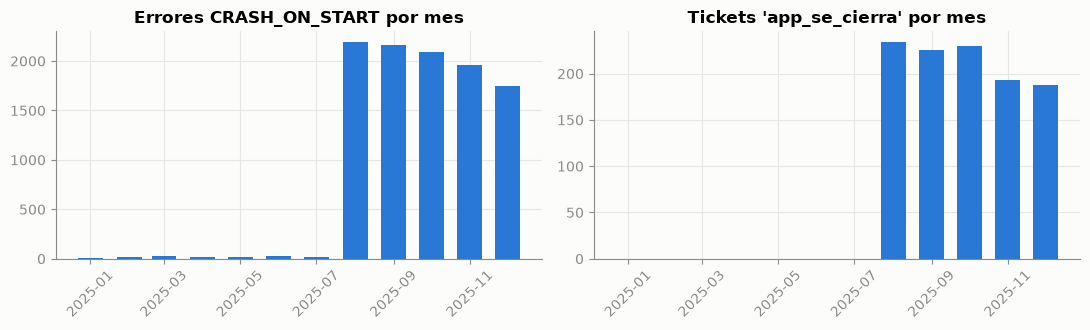

version_app,5.3.3,5.4.0,web
codigo_error,,,
CRASH_ON_START,151,10090,24
NET_ERR,654,0,101
TIMEOUT,813,0,118


In [14]:
ev = io.read(LAKE, "silver", "eventos")
cr = ev[ev.codigo_error == "CRASH_ON_START"].groupby(ev.ts.dt.to_period("M")).size()
meses = pd.period_range("2025-01", "2025-12", freq="M")
cr = cr.reindex(meses, fill_value=0)
ap = tk[tk.categoria == "app_se_cierra"].groupby(tk.creado_en.dt.to_period("M")).size().reindex(meses, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(cr.index.to_timestamp(), cr.values, width=20, color=AZUL); axes[0].set_title("Errores CRASH_ON_START por mes")
axes[1].bar(ap.index.to_timestamp(), ap.values, width=20, color=AZUL); axes[1].set_title("Tickets 'app_se_cierra' por mes")
for a in axes: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
display(pd.crosstab(ev[ev.tipo == "error_app"].codigo_error, ev[ev.tipo == "error_app"].version_app))

## 5. Supuestos sobre el significado de los campos
| Campo | Supuesto |
|---|---|
| `clientes.estado_actual` | Estado al 2025-12-31. Solo para validar; nunca como feature. |
| `clientes.fecha_alta` | = inicio de la primera suscripción (coincide 100 %). |
| `contactado_por_retencion` / `fecha_contacto_retencion` | Último contacto de retención; reactivo (días antes de cancelar). 76 fechas previas al alta → error de registro (flag). |
| `suscripciones.motivo_cancelacion = cambio_plan` | Cierre técnico por cambio de plan; el cliente continúa. |
| `facturas.fecha_carga` | Momento en que la factura existe en el sistema; las features usan facturas con `fecha_carga <= corte`. |
| `facturas.fecha_pago` | Se actualiza sin registro de cuándo; pago conocido solo si `fecha_pago <= corte`. |
| `facturas.monto` | Precio cobrado ese mes; el Básico sube a 23.900 en abr-2025. "Mensualidad actual" = precio de lista vigente del plan activo. |
| `tickets.csat` | Satisfacción 1–5; nula en tickets abiertos y en 22 % de resueltos B (no se imputa). |
| Tickets esquema B `cliente.segmento` | Coincide 100 % con CRM; se usa el del CRM. |
| `eventos` | Solo 2025 y solo 2.418 clientes tienen eventos; "sin eventos" es información (no uso de app o cliente sin app). |
| Fechas de corte | Inclusivas: un hecho del día del corte (hora local) se considera conocido. |

## 6. Implicaciones para Gold / modelado
1. Features **siempre** calculadas al corte con la misma función para entrenamiento y puntuación (spine en `gold/spine`).
2. Excluir `estado_actual`, `motivo_cancelacion`, `fecha_fin` y contactos posteriores al corte.
3. Validación temporal: entrenar en cortes de marzo/junio y validar en septiembre (la tasa de churn crece → revisar calibración).
4. Tickets anteriores a jun-2025 vienen del esquema A con menos detalle (sin respuesta del agente): las features de texto deben funcionar con ambos.
5. Los eventos solo cubren 2025: para el corte de marzo hay ~3 meses de historia de uso; usar ventanas cortas (30/90 días).